# Models > Classification and Regression Trees

<div class="alert alert-info">Estimate, prune, and interpret a regression tree</div>

<!-- pyrsm-teaching-note: roadmap -->
## Teaching Roadmap

Use this notebook to teach regression trees as a sequence of yes/no questions about the explanatory variables. Each answer sends an observation further down the tree until it reaches a terminal node (a *leaf*); the prediction is the average of the response for the estimation data in that leaf. Students should (1) see how a tree that is grown too far fits noise, (2) prune it with cross-validation, (3) trace the tree's R-squared back to its splits, and (4) use prediction, partial dependence, and ICE plots to find the interaction the tree discovered on its own. Trees do not need standardized variables: a split only depends on the *order* of the values.

In [1]:
import polars as pl
import pyrsm as rsm

In [2]:
## setup pyrsm for autoreload
%reload_ext autoreload
%autoreload 2
%aimport pyrsm

### Example: Catalog sales

We have access to data from a company selling men's and women's apparel through mail-order catalogs (dataset `catalog`). The company maintains a database on past and current customers' value and characteristics. Value is determined as the total \$ sales to the customer in the last year. The data are a random sample of 200 customers from the company's database.

The catalog company is interested in redesigning their Customer Relationship Management (CRM) strategy. We will estimate a regression tree for last year's sales (`Sales`) using household income (`Income`, in \$1,000), the size of the household (`HH_size`), and the age of the head of the household (`Age`), and compare it with a linear regression on the same variables.

In [3]:
# load example data from the pyrsm library
catalog = pl.read_parquet(
    "https://github.com/radiant-ai-hub/pyrsm/raw/refs/heads/main/examples/data/model/catalog.parquet"
)
catalog

id,Sales,Income,HH_size,Age
i32,f64,f64,i32,f64
1,178.63,93.0,4,55.0
2,338.59,79.0,5,35.0
3,210.26,70.0,4,64.0
4,378.64,95.0,2,39.0
5,227.09,119.0,2,43.0
6,329.95,43.0,6,55.0
7,259.13,90.0,5,54.0
8,311.09,107.0,6,62.0
9,416.68,106.0,3,64.0


In [4]:
# format the data description
rsm.md(
    "https://raw.githubusercontent.com/radiant-ai-hub/pyrsm/refs/heads/main/examples/data/model/catalog_description.md"
)

## Catalog sales

### Description

Data from a company selling men's and women's apparel through mail-order catalogs. The company maintains a database on past and current customers' value and characteristics. Value is determine as the total $ sales to the customer in the last year. The data are a random sample of 200 customers from the company's database.

### Variables

A data frame with 200 observations on 4 variables

- id = Customer id
- Sales =	Total sales (in $) to a household in the past year
- Income = Household income ($1000) 
- HH.size = Size of the household (# of people) 
- Age = Age of the head of the household

<!-- pyrsm-teaching-note: crtree-reg-how -->
### How a regression tree is grown

A regression tree starts with all 200 customers in one node and predicts the average sales, \$265.48, for everyone. The *sum of squared errors* (SSE) of that prediction is the total variation in `Sales`. The tree then looks at every explanatory variable and every possible cut-off (e.g., `Income < 61.5`) and picks the split that lowers the SSE the most: the SSE of the two groups, each predicted by its own average. It repeats this within each group, and so on.

Two settings control how far it goes:

- `cp` (complexity parameter, default 0.001): a split is only made if it lowers the SSE by at least `cp` times the total SSE
- `minsplit` (default 2): the minimum number of observations a node needs before it can be split

With these defaults the tree keeps splitting until it nearly memorizes the data.

### Step 1: Grow a large tree

In [5]:
full = rsm.model.crtree(
    {"catalog": catalog},
    rvar="Sales",
    evar=["Income", "HH_size", "Age"],
    mod_type="regression",
)
full.cptable

CP,nsplit,rel error,xerror,xstd
f64,i64,f64,f64,f64
0.20647,0,1.0,1.010506,0.098388
0.088538,1,0.79353,0.869837,0.083038
0.069741,2,0.704992,0.79113,0.07873
0.038468,3,0.635251,0.691051,0.07171
0.018657,4,0.596783,0.670248,0.063212
0.018231,5,0.578126,0.772475,0.0704
0.017186,8,0.523432,0.777244,0.070803
0.013767,9,0.506246,0.791289,0.071337
0.0125,13,0.450867,0.923226,0.08426


The *complexity parameter table* lists the trees of every size the algorithm grew, from the root (`nsplit` = 0) to the full tree with 100 splits.

- `rel error` is the SSE of the tree divided by the total SSE, on the *estimation* data. It always goes down: the full tree has a relative error of 0.037, an in-sample R-squared of 0.963.
- `xerror` is the same ratio from 10-fold *cross-validation*: the tree is grown on 9/10 of the data and the errors are measured on the 1/10 it did not see, ten times over. `xstd` is its standard error.

For the full tree `xerror` is 1.23: on data it has not seen, the 100-split tree predicts *worse* than simply using the average sales for every customer (`xerror` = 1). The tree fits noise.

### Step 2: Prune the tree with cross-validation

The prune plot shows the cross-validated relative error (`xerror`) for every tree size.

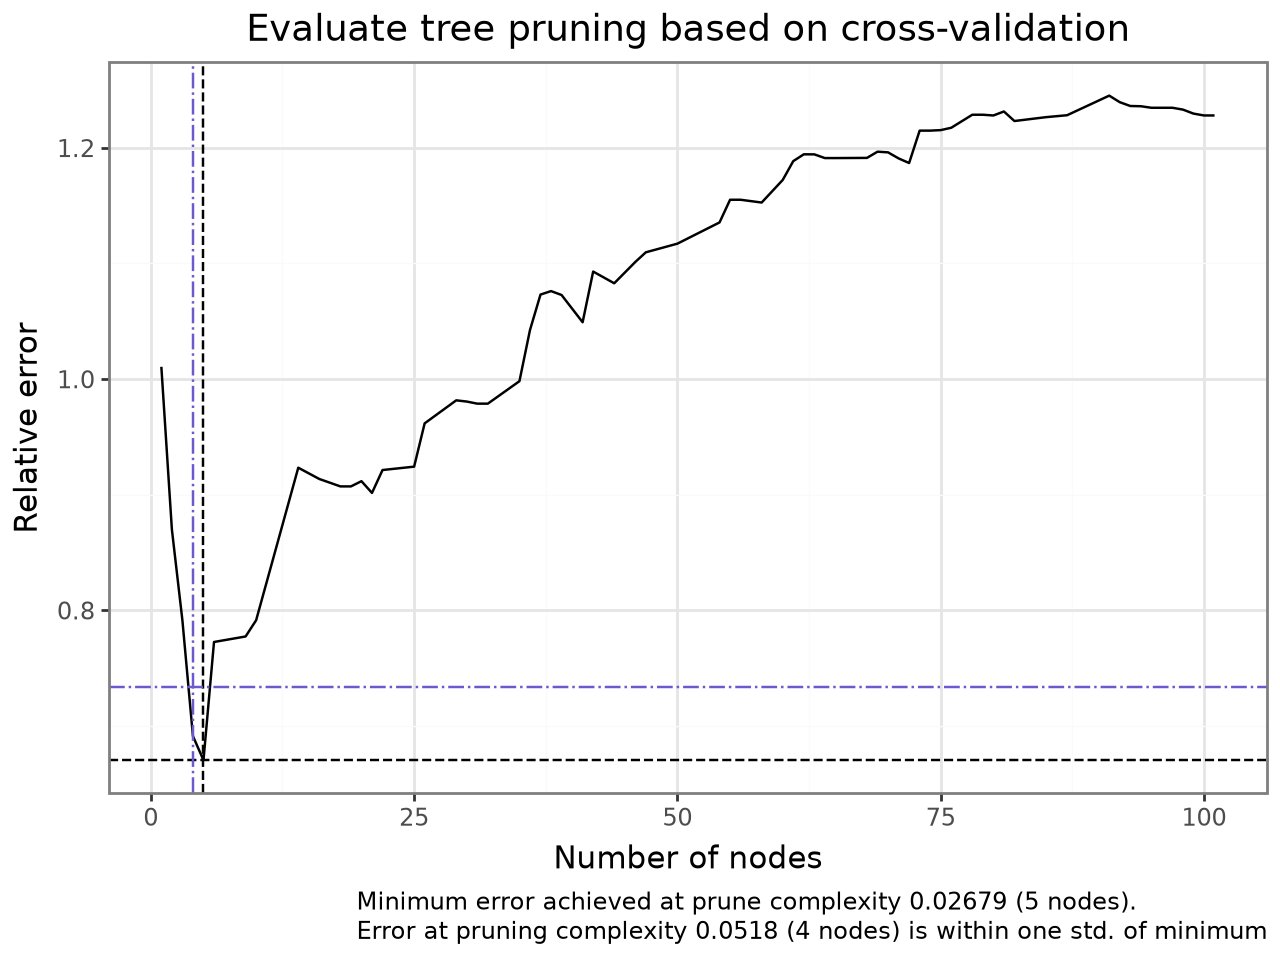

In [6]:
full.plot("prune")

<!-- pyrsm-teaching-note: crtree-reg-prune -->
The error drops quickly over the first few splits and then rises as the tree starts to fit noise.

- The black dashed lines mark the minimum cross-validated error: 5 nodes, at a pruning complexity of 0.02679.
- The blue dash-dot lines mark the *one standard error rule*: the smallest tree whose error is within one standard error of the minimum, here 4 nodes at a pruning complexity of 0.0518. Its error is statistically indistinguishable from the minimum, and it is simpler.

We prune with `pcp=0.05`. Any value between 0.0385 and 0.0697 (the `CP` values of the 3- and 2-split trees in the table above) gives the same 4-node tree. `nodes=4` (the maximum number of terminal nodes) does the same.

In [7]:
reg_tree = rsm.model.crtree(
    {"catalog": catalog},
    rvar="Sales",
    evar=["Income", "HH_size", "Age"],
    mod_type="regression",
    pcp=0.05,
)
reg_tree.summary()

Regression tree
Data                 : catalog
Response variable    : Sales
Explanatory variables: Income, HH_size, Age
Complexity parameter : 0.001
Minimum observations : 2
Nr obs               : 200

node), split, n, deviance, yval
      * denotes terminal node

1) root 200 2327980.00 265.4797  
  2) Income< 61.5 80  686513.50 205.4385  
    4) HH_size< 4.5 60  392069.00 176.1330 *
    5) HH_size>=4.5 20   88329.55 293.3550 *
  3) Income>=61.5 120 1160808.00 305.5071  
    6) Income< 94.5 71  545679.70 274.9500 *
    7) Income>=94.5 49  452773.00 349.7837 *


Each line is a node: its number, the split that leads to it, the number of observations `n`, the SSE of the node (`deviance`), and the prediction (`yval`, the average sales in the node). Terminal nodes are marked with `*`.

- The first split is on `Income`: 80 households with income below \$61,500 spend \$205.44 on average, the 120 households above it \$305.51.
- Among the lower-income households, those with 5 or more people (`HH_size >= 4.5`; household size is a whole number, so `< 4.5` means 4 or fewer) spend \$293.36, smaller households \$176.13.
- Among the higher-income households, `Income >= 94.5` spend \$349.78 and the others \$274.95.

`Age` is not used, and household size only matters for lower-income households: the tree found an *interaction* without being told to look for one.

The tree plot shows the same tree. In a notebook (or VS Code) hover over a node to see the number of observations and the prediction. Use `orient="TD"` for a top-down tree.

In [8]:
reg_tree.plot("tree")

graph LR
id1[Income] --- |< 61.5|id2[HH_size<br><b>n:</b> 80<br><b>b:</b> 205.44]
id2[HH_size] --- |< 5|id4[<b>n:</b> 60<br><b>b:</b> 176.13]
id3[Income] --- |< 94.5|id6[<b>n:</b> 71<br><b>b:</b> 274.95]
id1[Income] --- |>=61.5|id3[Income<br><b>n:</b> 120<br><b>b:</b> 305.51]
id2[HH_size] --- |>= 5|id5[<b>n:</b> 20<br><b>b:</b> 293.35]
id3[Income] --- |>=94.5|id7[<b>n:</b> 49<br><b>b:</b> 349.78]
classDef default fill:none, bg:none, stroke-width:0px;
      classDef leaf fill:#9ACD32,stroke:#333,stroke-width:1px;
      classDef chance fill:#FF8C00,stroke:#333,stroke-width:1px;
      classDef chance_with_cost fill:#FF8C00,stroke:#333,stroke-width:3px,stroke-dasharray:4,5;
      classDef decision fill:#9ACD32,stroke:#333,stroke-width:1px;
      classDef decision_with_cost fill:#9ACD32,stroke:#333,stroke-width:3px,stroke-dasharray:4,5;
      class id4,id6,id5,id7 leaf;
click id1 callback "<b>n:</b> 200<br><b>b:</b> 265.48"
click id2 callback "<b>n:</b> 80<br><b>b:</b> 205.44"
click id3 callback "<b>n:</b> 120<br><b>b:</b> 305.51"

<!-- pyrsm-teaching-note: crtree-reg-sse -->
### Where does the tree's R-squared come from?

`node_table()` has one row per node, in the same order as the summary. `sse` is the sum of squared errors of the node's prediction, and SSE *adds up*: a node's SSE equals the SSE of its two children plus what its split removes. `removed` is the share of the total SSE (the root's) that a node's split removes.

In [9]:
nt = reg_tree.node_table()
nt.select("node", "split", "leaf", "n", "prediction", "sse", "removed")

node,split,leaf,n,prediction,sse,removed
i64,str,bool,i64,f64,f64,f64
1,"""""",false,200,265.47965,2.3280e6,0.20647
2,"""Income < 61.5""",false,80,205.4385,686513.51862,0.088538
4,"""HH_size < 5""",true,60,176.133,392069.01026,null
5,"""HH_size >= 5""",true,20,293.355,88329.5491,null
3,"""Income >= 61.5""",false,120,305.507083,1.1608e6,0.069741
6,"""Income < 94.5""",true,71,274.95,545679.7214,null
7,"""Income >= 94.5""",true,49,349.783673,452773.005739,null


In [10]:
# SSE with the root set to 100, and the R-squared as the sum of what the splits remove
total_sse = nt["sse"][0]
print(f"Total SSE: {total_sse:,.0f}")
print(nt.select("node", "split", (100 * pl.col("sse") / total_sse).round(1).alias("sse (total = 100)")))
print(f"R-squared (sum of 'removed'): {nt['removed'].sum():.3f}")

Total SSE: 2,327,980
shape: (7, 3)
┌──────┬────────────────┬───────────────────┐
│ node ┆ split          ┆ sse (total = 100) │
│ ---  ┆ ---            ┆ ---               │
│ i64  ┆ str            ┆ f64               │
╞══════╪════════════════╪═══════════════════╡
│ 1    ┆                ┆ 100.0             │
│ 2    ┆ Income < 61.5  ┆ 29.5              │
│ 4    ┆ HH_size < 5    ┆ 16.8              │
│ 5    ┆ HH_size >= 5   ┆ 3.8               │
│ 3    ┆ Income >= 61.5 ┆ 49.9              │
│ 6    ┆ Income < 94.5  ┆ 23.4              │
│ 7    ┆ Income >= 94.5 ┆ 19.4              │
└──────┴────────────────┴───────────────────┘
R-squared (sum of 'removed'): 0.365


The total SSE is 2,327,980. The `Income` split at the root removes 20.6% of it, the `HH_size` split 8.9%, and the second `Income` split 7.0%. Together they remove 36.5%: that is the tree's R-squared on the estimation data. The four terminal nodes keep the remaining 63.5 of the 100 (16.8 + 3.8 + 23.4 + 19.4, up to rounding).

You can check this by hand: the root split leaves 686,514 (node 2) + 1,160,808 (node 3) = 1,847,322 of 2,327,980, so it removes 480,658, or 20.6%.

How does this compare to a linear regression with the same three variables?

In [11]:
reg = rsm.model.regress({"catalog": catalog}, rvar="Sales", evar=["Income", "HH_size", "Age"])
reg.summary()

Linear regression (OLS)
Data                 : catalog
Response variable    : Sales
Explanatory variables: Income, HH_size, Age
Null hyp.: the effect of x on Sales is zero
Alt. hyp.: the effect of x on Sales is not zero



┌───────────┬─────────────┬───────────┬─────────┬─────────┬─────┐
│ index     ┆ coefficient ┆ std.error ┆ t.value ┆ p.value ┆     │
╞═══════════╪═════════════╪═══════════╪═════════╪═════════╪═════╡
│ Intercept ┆ 45.359      ┆ 43.089    ┆ 1.053   ┆ 0.294   ┆     │
│ Income    ┆ 1.775       ┆ 0.217     ┆ 8.181   ┆ < .001  ┆ *** │
│ HH_size   ┆ 22.122      ┆ 4.19      ┆ 5.279   ┆ < .001  ┆ *** │
│ Age       ┆ 0.449       ┆ 0.768     ┆ 0.585   ┆ 0.559   ┆     │
└───────────┴─────────────┴───────────┴─────────┴─────────┴─────┘

Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

R-squared: 0.331, Adjusted R-squared: 0.321
F-statistic: 32.325 df(3, 196), p.value < 0.001
Nr obs: 200


<!-- pyrsm-teaching-note: crtree-reg-compare -->
The linear regression has an R-squared of 0.331, the tree 0.365 with only four different predictions. The two models also tell a different story about household size: the regression adds \$22.12 in sales for every extra person, for every household, while the tree says household size only matters below an income of \$61,500. Both R-squared values, however, are measured on the data the models were estimated on, and the tree was chosen *because* it fits these data well. The cross-validated relative error of the 4-node tree is a fairer measure:

In [12]:
cv = full.cptable.filter(pl.col("nsplit") == 3)
print(cv)
print(f"Cross-validated R-squared of the 4-node tree: {1 - cv['xerror'][0]:.3f}")

shape: (1, 5)
┌──────────┬────────┬───────────┬──────────┬─────────┐
│ CP       ┆ nsplit ┆ rel error ┆ xerror   ┆ xstd    │
│ ---      ┆ ---    ┆ ---       ┆ ---      ┆ ---     │
│ f64      ┆ i64    ┆ f64       ┆ f64      ┆ f64     │
╞══════════╪════════╪═══════════╪══════════╪═════════╡
│ 0.038468 ┆ 3      ┆ 0.635251  ┆ 0.691051 ┆ 0.07171 │
└──────────┴────────┴───────────┴──────────┴─────────┘
Cross-validated R-squared of the 4-node tree: 0.309


On data the tree has not seen it explains about 31% of the variation in sales, a little less than its in-sample 36.5%. With only 200 customers, a different sample (or a different `seed` for the cross-validation) could give a different tree. That instability is the main weakness of a single tree, and the reason *random forests* average many trees grown on resampled data (see the [random forest regression notebook](model-rforest-regression.ipynb)).

### Which variables matter?

Permutation importance shuffles one explanatory variable at a time, breaking its link with sales, and measures how much the R-squared drops.

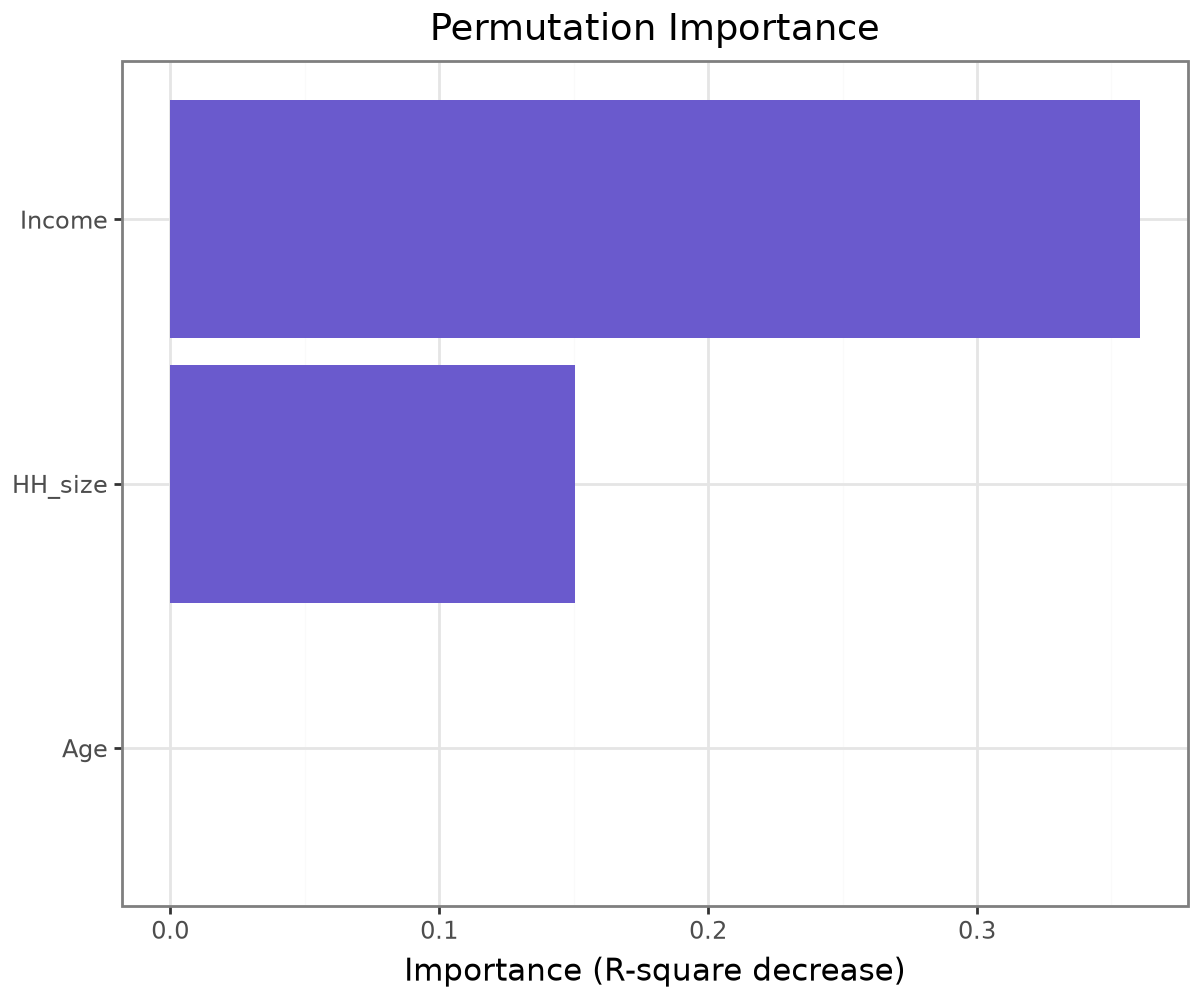

In [13]:
reg_tree.plot("pip")

Shuffling `Income` lowers the R-squared by 0.36, shuffling `HH_size` by 0.15. `Age` is not in the tree, so shuffling it changes nothing.

<!-- pyrsm-teaching-note: crtree-reg-pdp -->
### Prediction plots and partial dependence

A prediction plot varies one variable over its range and keeps the other variables at their average (or most common level). A partial dependence plot (PDP) instead sets the variable to each value *for every customer* and averages the predictions.

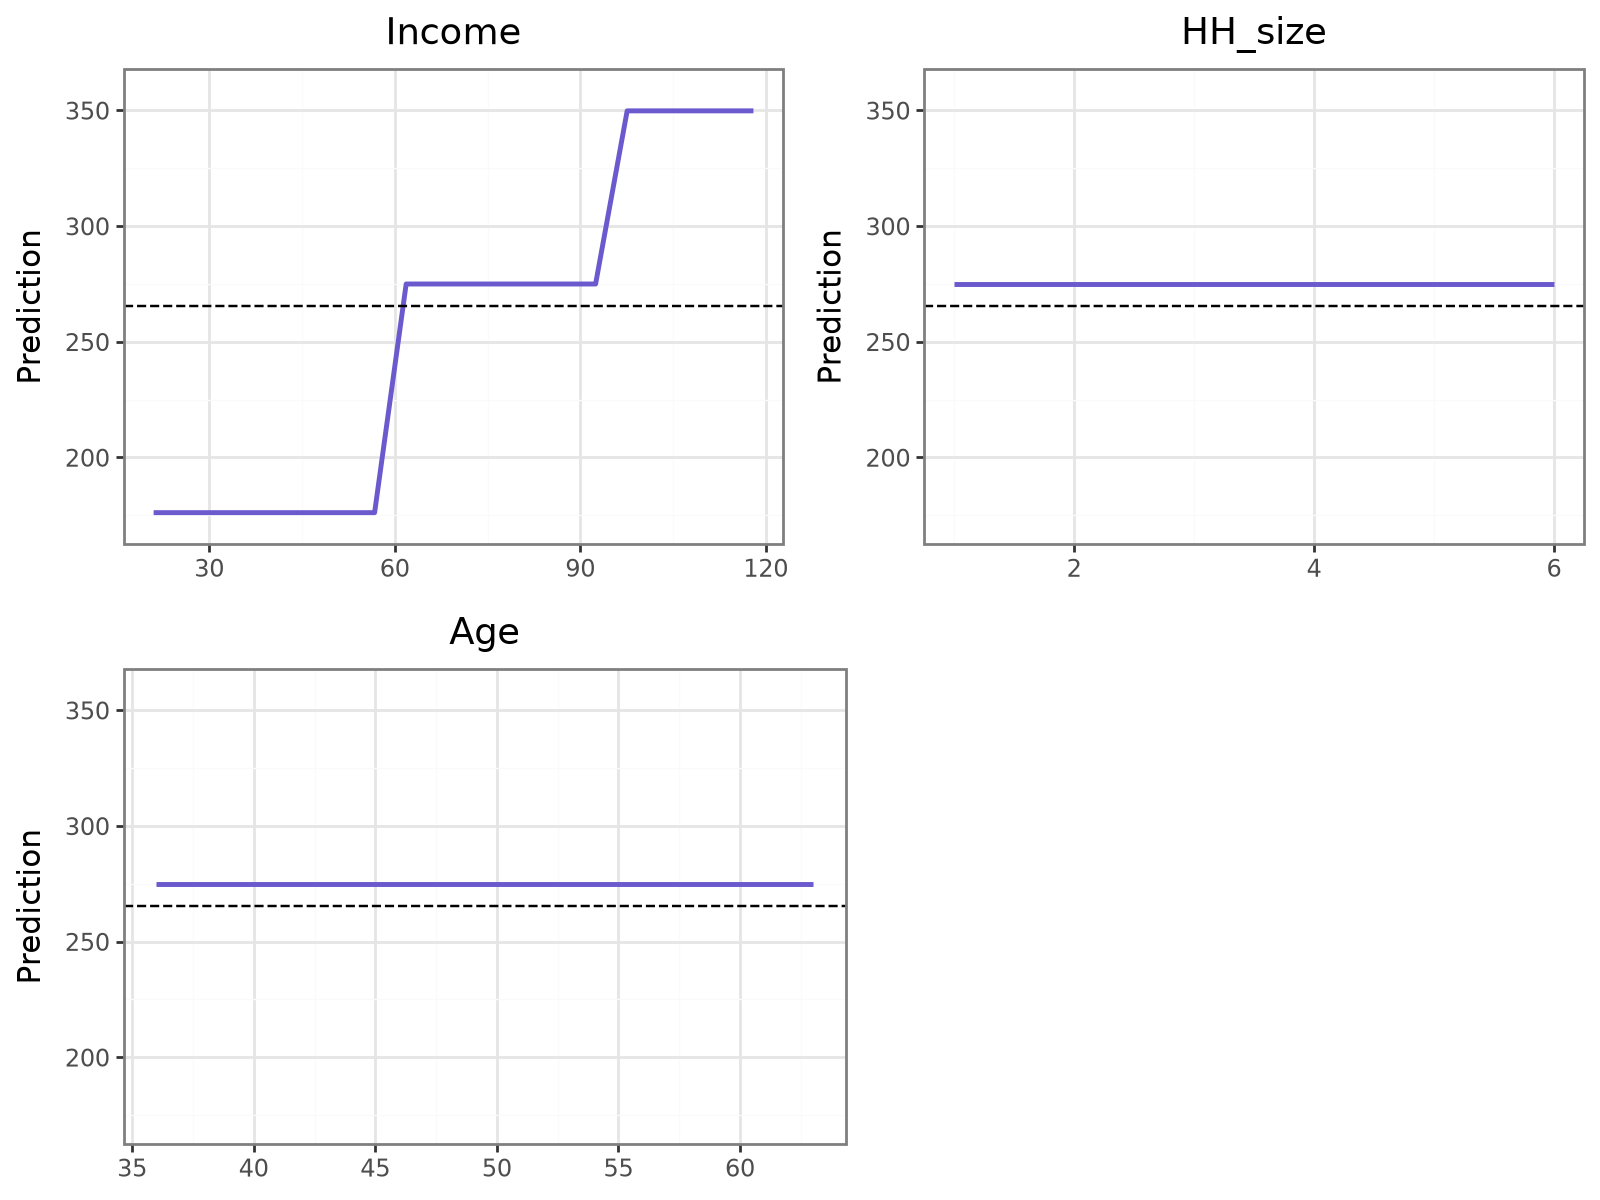

In [14]:
reg_tree.plot("pred")

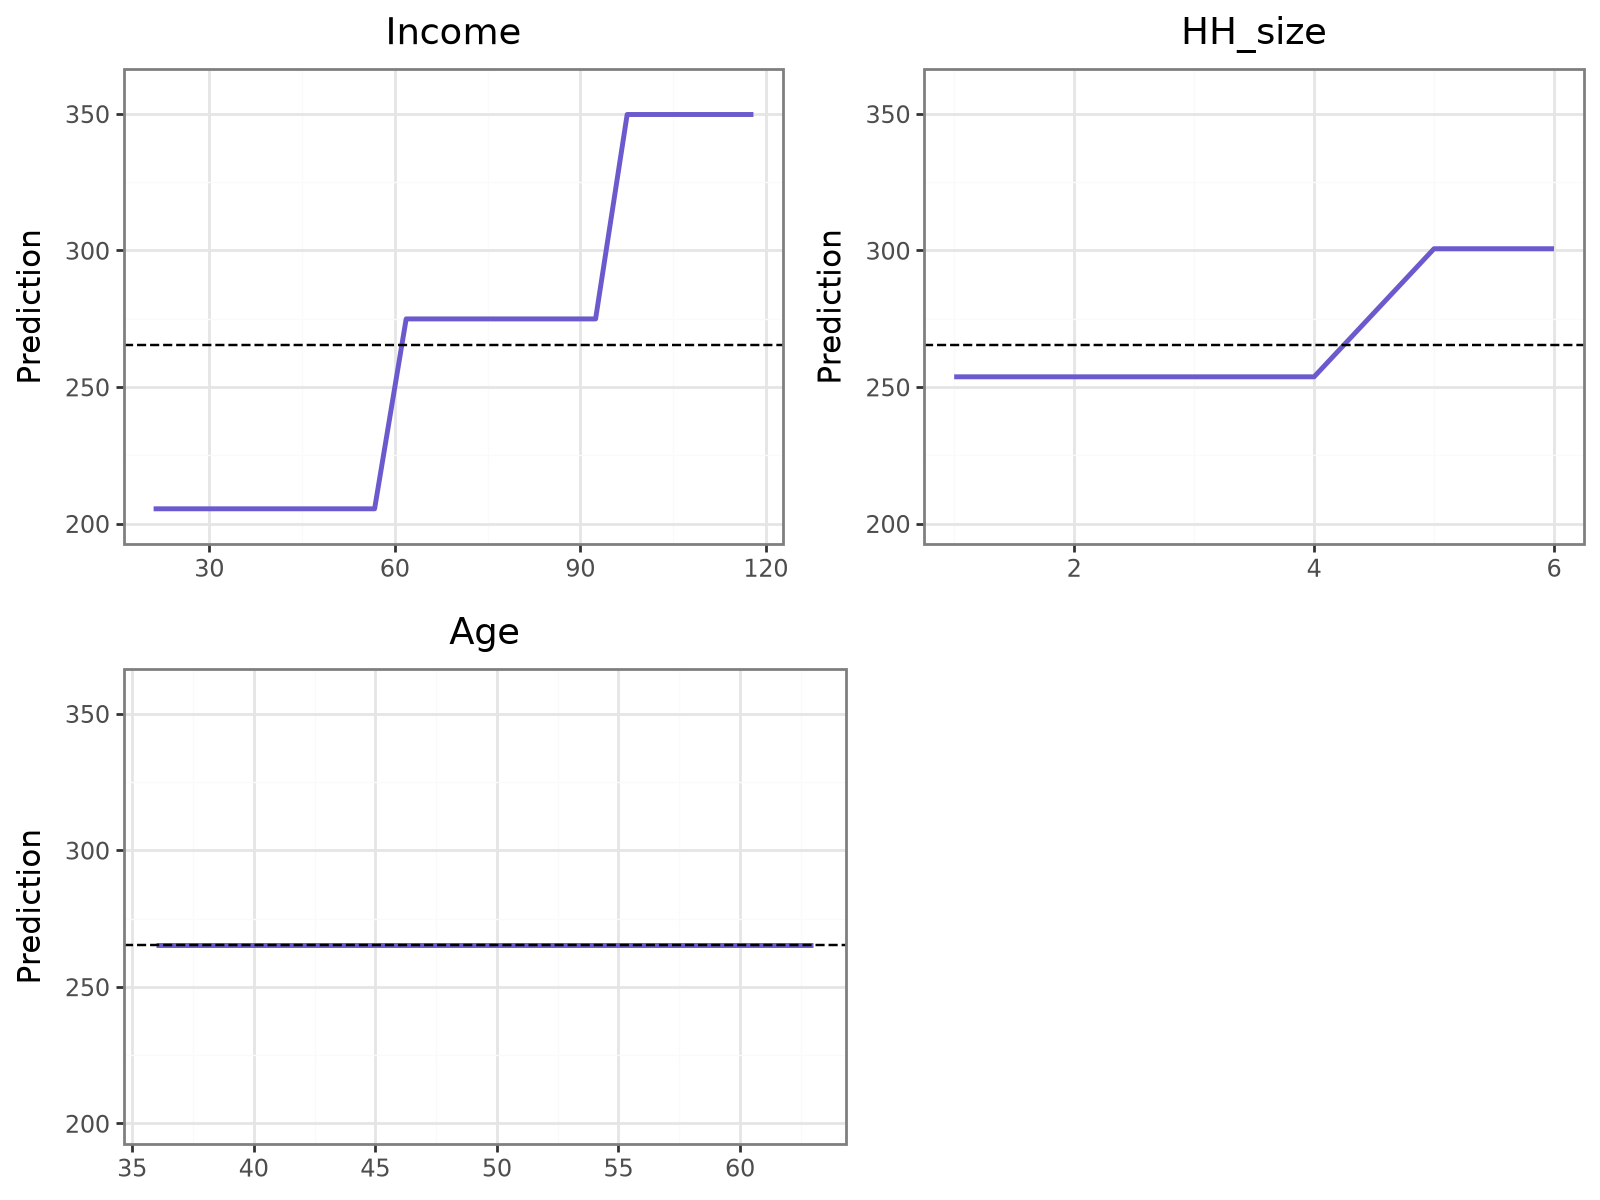

In [15]:
reg_tree.plot("pdp")

Both plots are *step functions*: a tree predicts a constant within each leaf, so predicted sales jump at the split points (\$61,500 and \$94,500 for income) and are flat in between.

The two plots differ for `HH_size`. In the prediction plot income is held at its average (about \$70,000), above the \$61,500 split, where household size plays no role: the line is flat. The PDP averages over all customers, including the 40% with lower incomes for whom household size does matter, so it shows a step between 4 and 5 people. When the two plots disagree, look for an interaction:

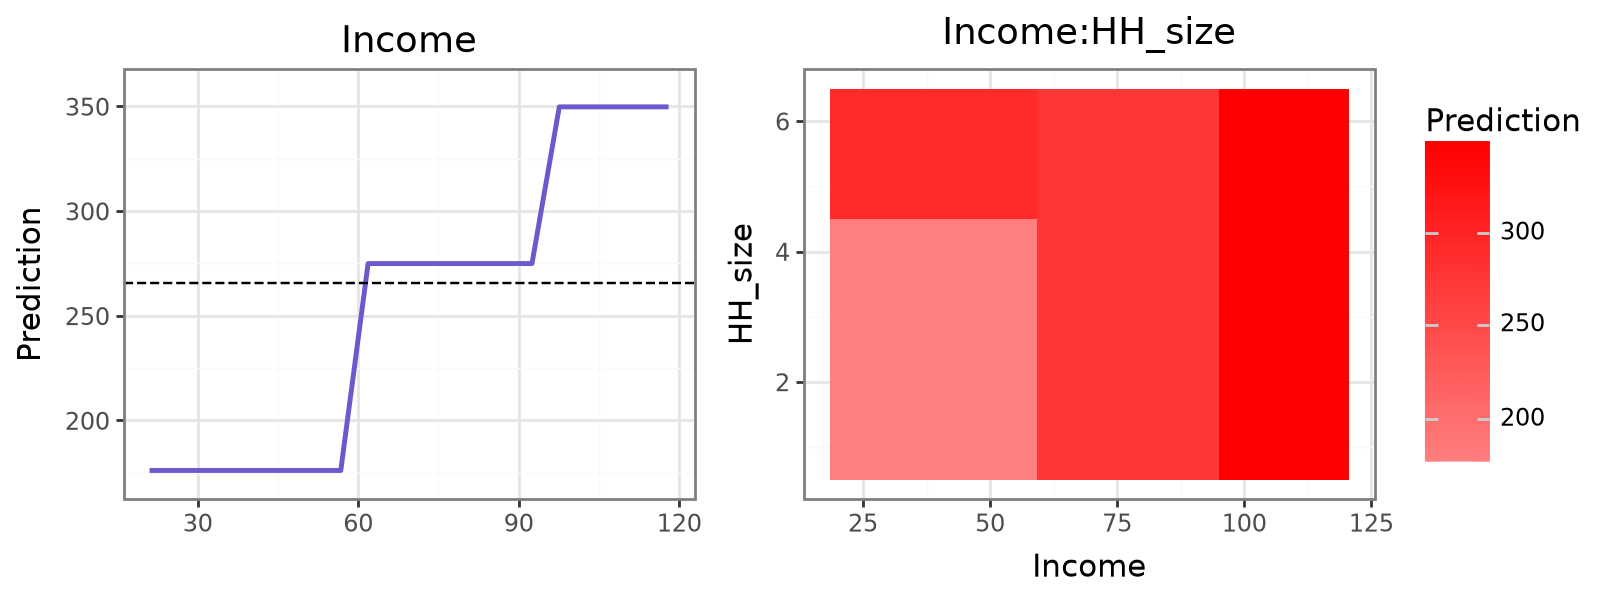

In [16]:
reg_tree.plot("pred", incl=["Income"], incl_int=["Income:HH_size"])

The interaction plot shows predicted sales for every combination of income and household size. Household size only changes the prediction (the color) on the left, below \$61,500.

*Individual conditional expectation* (ICE) lines show the same change for individual customers (a sample of up to 100), behind the average PDP line:

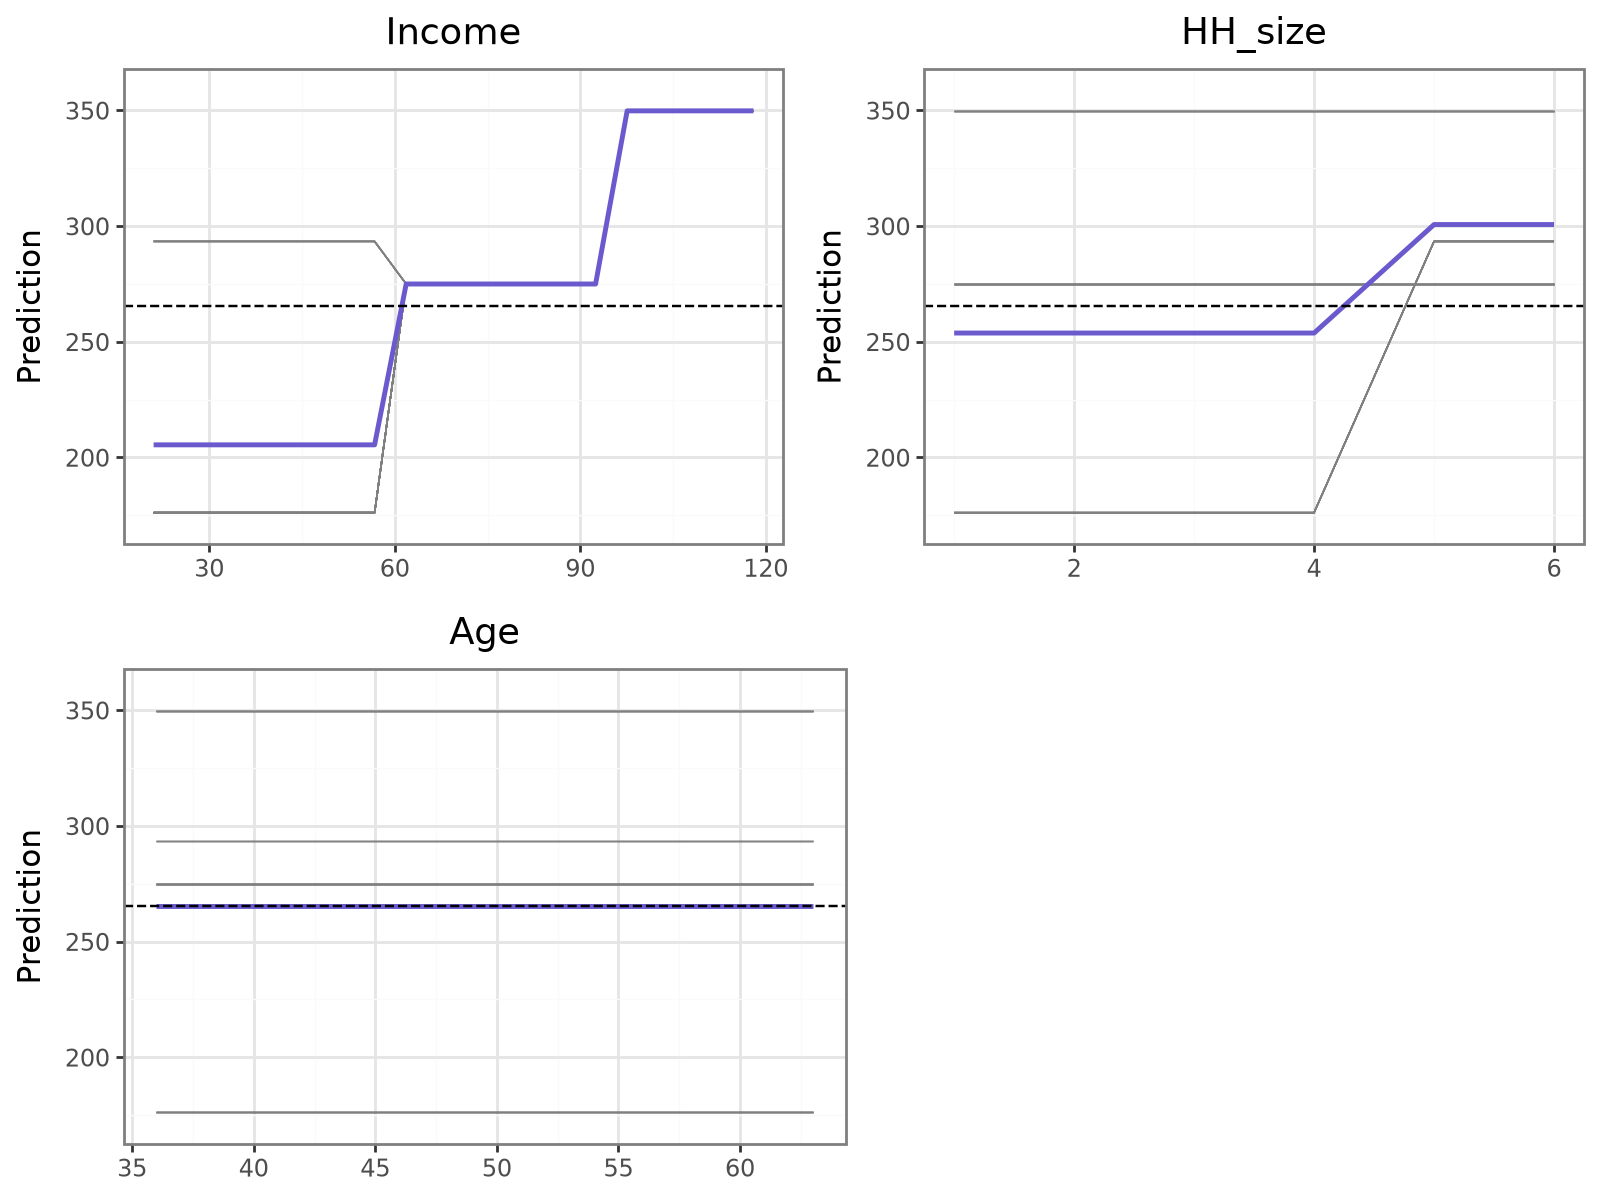

In [17]:
reg_tree.plot("pdp", ice=True)

With four leaves there are only a few different ICE lines, and many customers share each one. For `HH_size` most lines are flat (higher-income customers) and some jump from \$176 to \$293 (lower-income customers). The average line hides this split; the ICE lines show it.

### Residuals

The dashboard shows the usual residual plots.

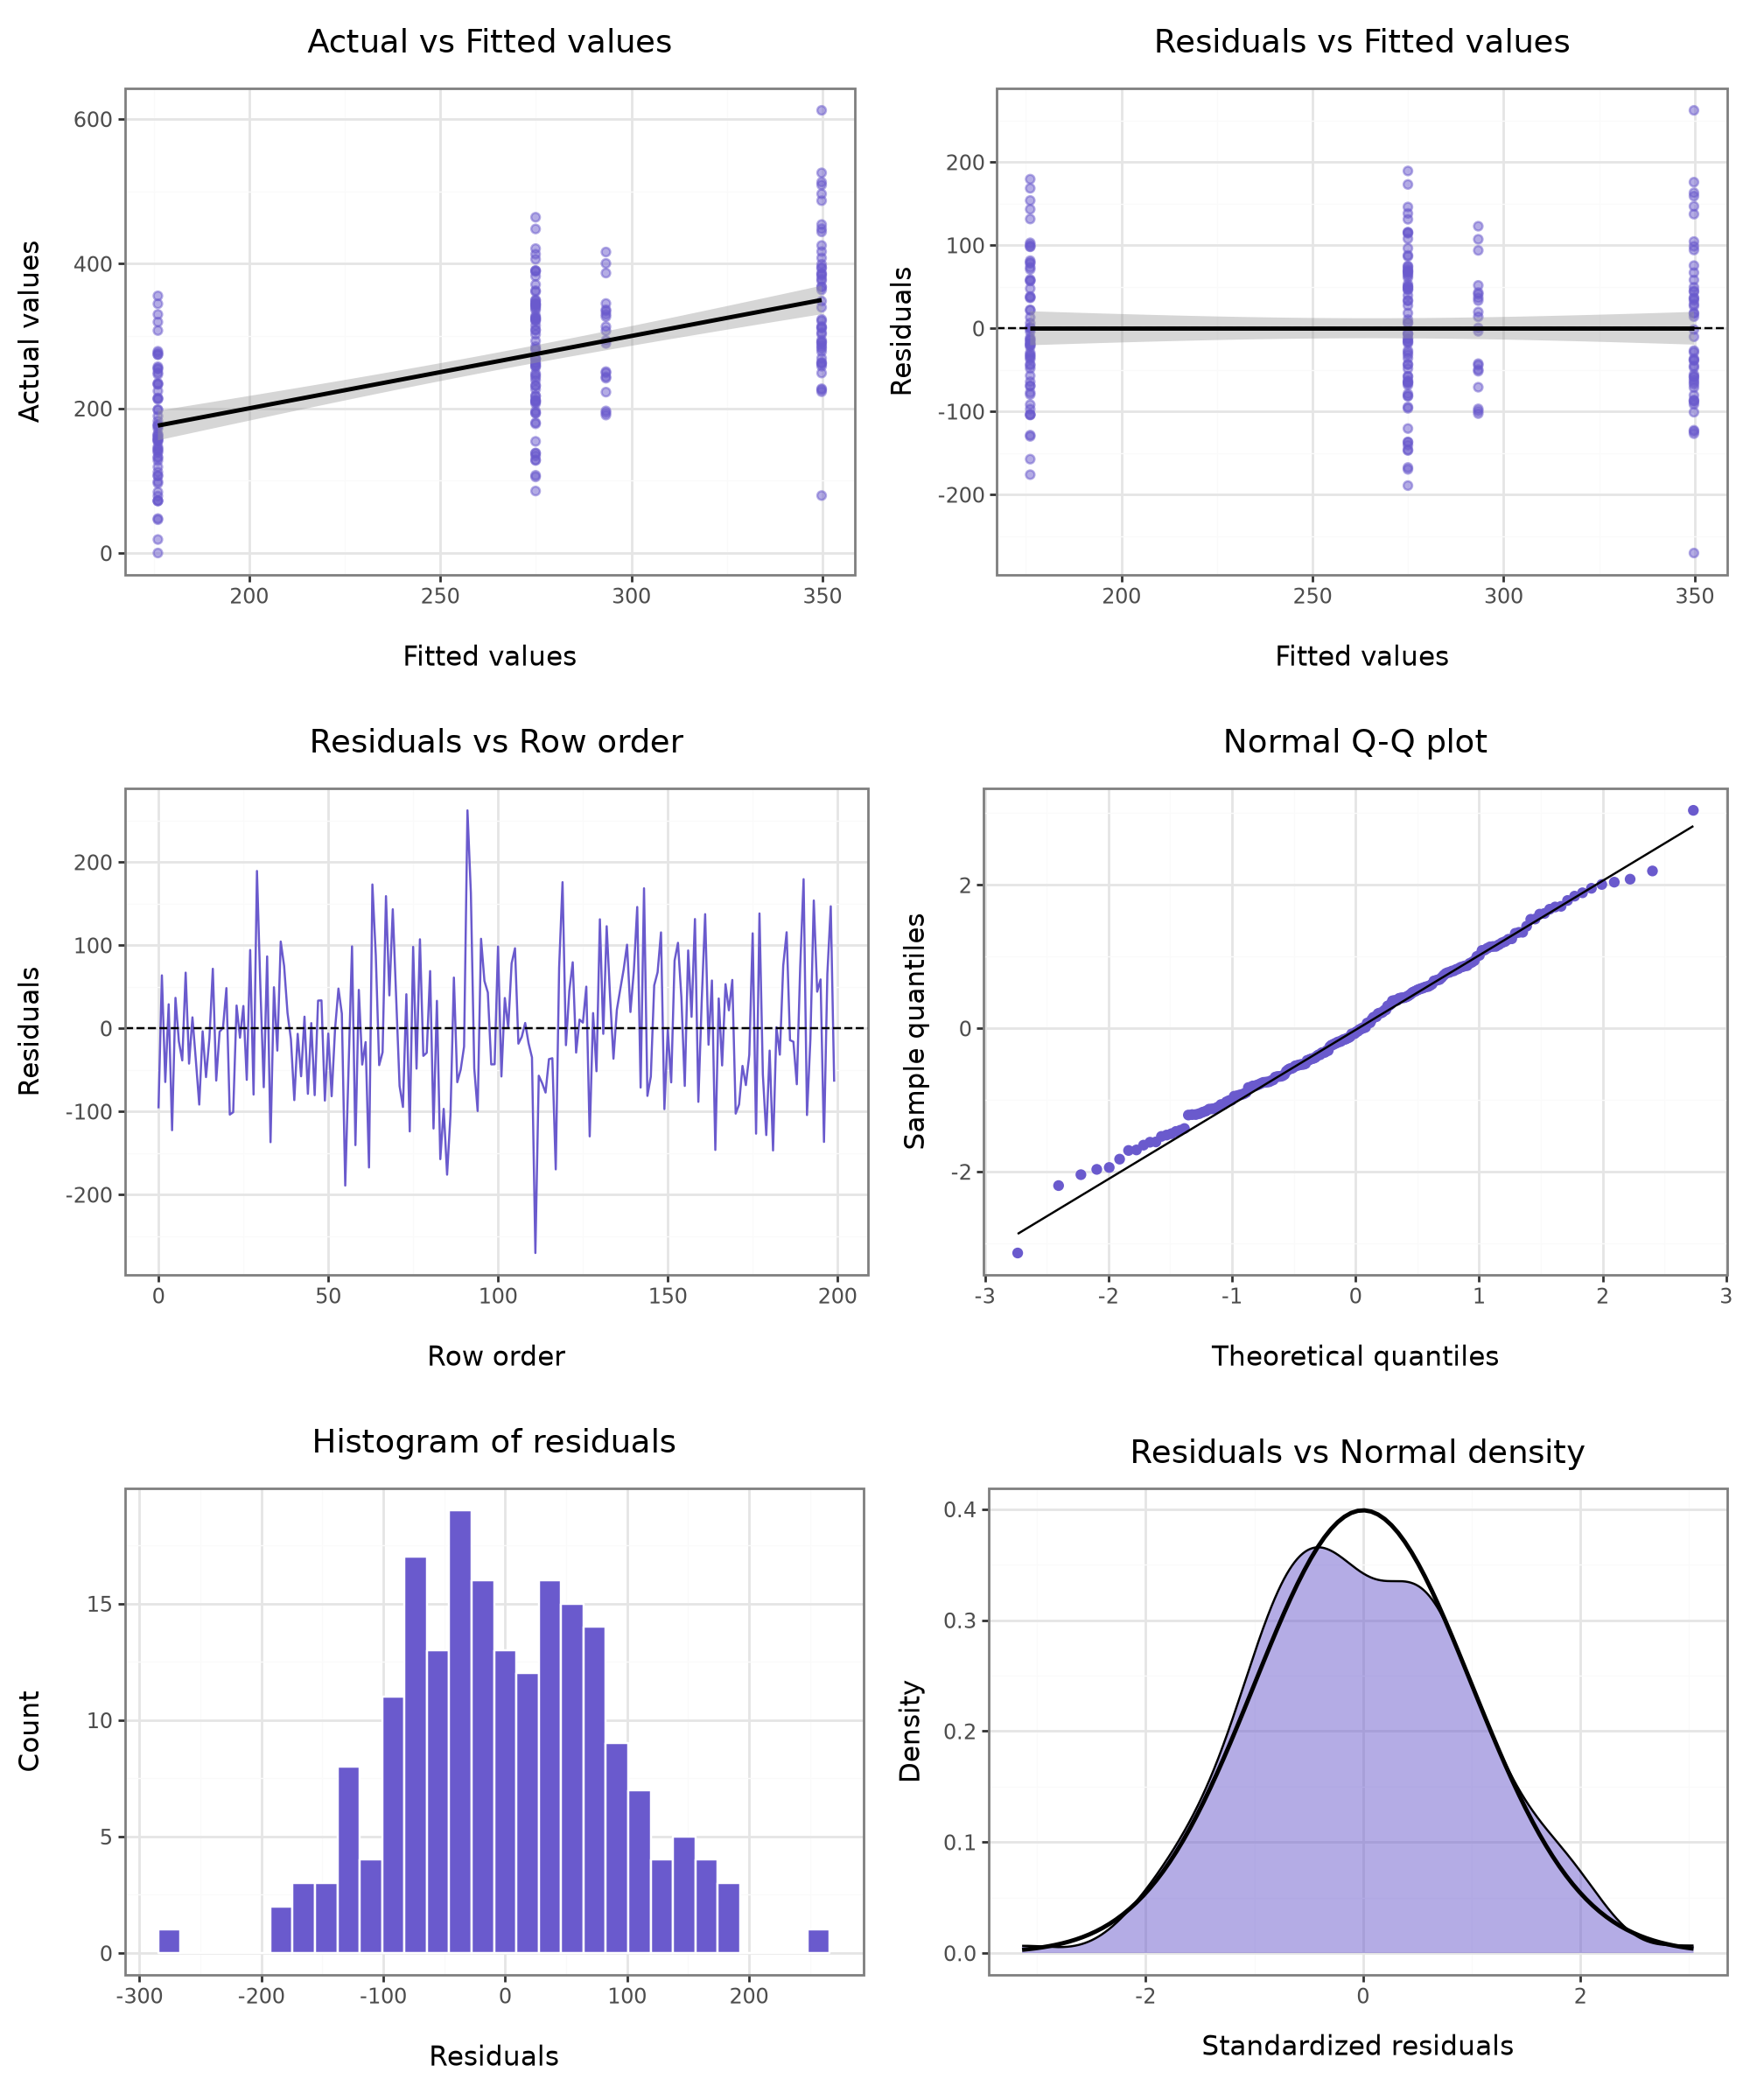

In [18]:
reg_tree.plot("dashboard")

A 4-node tree makes only four different predictions, so the fitted values form four vertical stripes. Within each stripe the residuals are the spread of sales around the leaf average. There is no curvature to look for: within a leaf the tree has nothing more to say.

### Predictions

Predict sales for households with an income of \$40,000, \$80,000, or \$120,000 and 2 or 5 people. Variables that are not specified (`Age`) are set to their mean.

In [19]:
reg_tree.predict(cmd={"Income": [40, 80, 120], "HH_size": [2, 5]})

Income,HH_size,Age,prediction
f64,i32,f64,f64
40.0,2,48.745,176.133
40.0,5,48.745,293.355
80.0,2,48.745,274.95
80.0,5,48.745,274.95
120.0,2,48.745,349.783673
120.0,5,48.745,349.783673


Household size changes the prediction only for the \$40,000 households (\$176.13 vs \$293.36). Above \$61,500 the tree ignores it, and above \$94,500 every household gets \$349.78.

<!-- pyrsm-teaching-note: crtree-reg-takeaways -->
### Takeaways

- A tree grown with a small `cp` fits noise. Use the prune plot and the one standard error rule to choose a pruning complexity (`pcp`) or a number of nodes (`nodes`).
- `node_table()` shows how each split lowers the SSE; the splits add up to the tree's R-squared.
- Trees find interactions on their own (household size only matters for lower incomes) and need no transformations or standardization, but they predict in steps and can change a lot with a different sample.
- Judge a tree, like any model, on data it has not seen: the cross-validated error, or a test set.